<a href="https://colab.research.google.com/github/ricvazquez/ColabFiles/blob/main/PracticaClasesNoBalanceadas_273509.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Práctica: Ejercicios sobre Clases No Balanceadas, Data Leakage (Pipeline) y SVM

Nombre: Ricardo Vazquez Macias

Matricula 273509

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score
from sklearn.metrics import f1_score, recall_score
import statsmodels.api as sm
from collections import Counter
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection
from statsmodels.stats.outliers_influence import variance_inflation_factor
from google.colab import drive

drive.mount('/content/drive')
df = pd.read_csv('drive/MyDrive/ClassFiles/compustat.csv')
print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   idx       at0       at1       at2       at3       at4       at5       at6  \
0    0  0.076753  0.066548  0.132170  4.257882  0.771988  0.669344  0.076278   
1    1  0.097633  0.087736  0.162879  4.141787  0.781934  0.702665  0.082633   
2    2  0.025683  0.022020  0.152882  3.140505  0.698522  0.598883  0.097905   
3    3  0.011354  0.008987  0.165670  2.927575  0.699374  0.553558  0.107831   
4    4  0.001675  0.001212  0.155509  3.120983  0.689971  0.499122  0.098458   

        at7       at8  ...      at11      at12      at13      at14      at15  \
0  2.898450  6.081867  ...  2.052378  0.372113  0.322636  0.250182  1.153351   
1  2.947445  6.272092  ...  1.968984  0.371728  0.334043  0.231646  1.112813   
2  2.971928  6.508112  ...  1.374306  0.305678  0.262075  0.220100  1.166375   
3  2.955952  6.588417  ...  1.173407  0.280317  0.221873  0.245524  1.

In [2]:
## Eliminamos la columna indice y separamos el dataset en dos en base a lo que queremos trabajar
x = df.drop(['idx','label'], axis=1)
y = df['label']
print(x.shape)
print(y.shape)

(13657, 20)
(13657,)


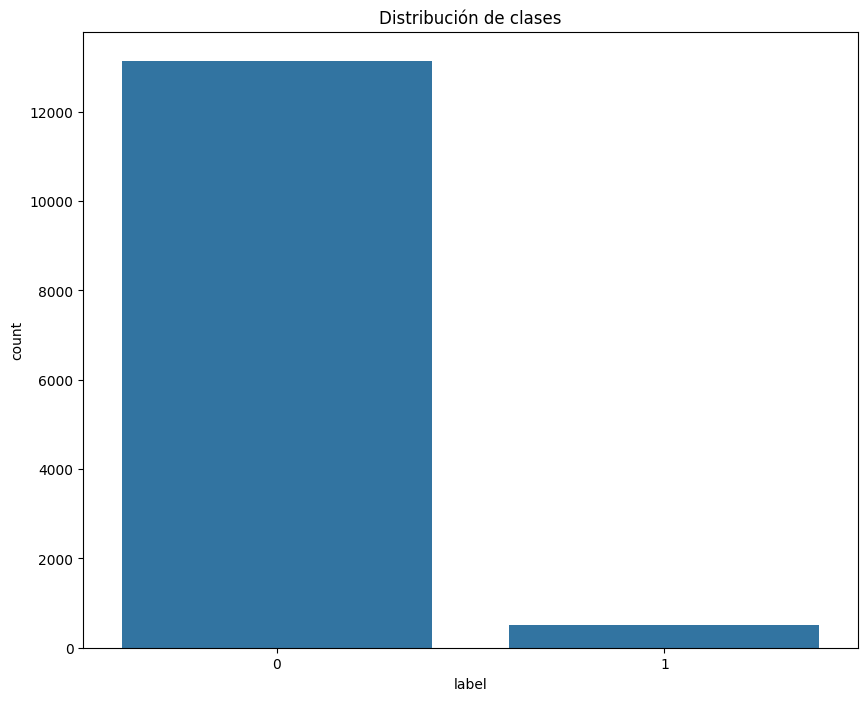

In [5]:
## Realizamos una grafica para ver como se distriuyen las clases de label
plt.figure(figsize=(10, 8))
sns.countplot(x='label', data=df)
plt.title('Distribución de clases')
plt.show()

In [20]:
## Revisamos los counts para ver proporciones de y
print(y.value_counts(normalize=True))

label
0    0.961924
1    0.038076
Name: proportion, dtype: float64


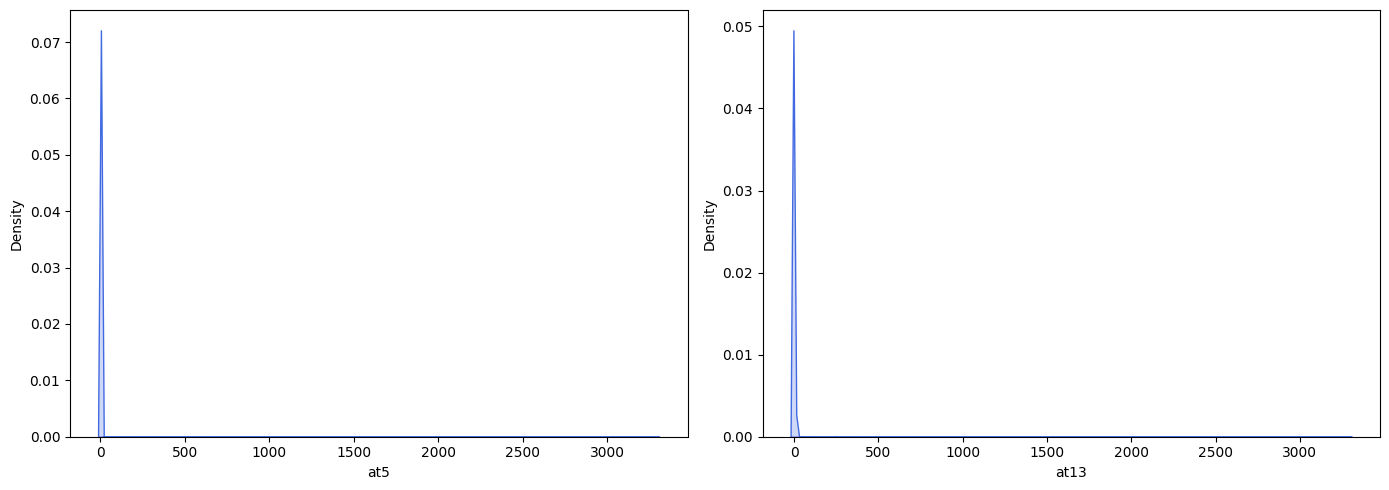

In [18]:
## Graficamos los ats 5 y 13 como lo pide la practica
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(x.iloc[:, 5], ax=axs[0], fill=True, color = 'royalblue')
sns.kdeplot(x.iloc[:, 13], ax=axs[1], fill=True, color = 'royalblue')
plt.tight_layout()
plt.show()

In [19]:
## Curiosa la grafica, verificamos viendo los valores de cada columna
print(x['at5'].value_counts())
print(x['at13'].value_counts())

at5
0.000000    71
0.460826     2
0.229883     2
0.523269     2
0.511584     2
            ..
0.238073     1
0.234541     1
0.220173     1
0.306018     1
0.405347     1
Name: count, Length: 13556, dtype: int64
at13
0.000000    19
0.145077     2
0.210792     2
0.332513     2
0.335830     2
            ..
0.293224     1
0.250230     1
0.240386     1
0.166544     1
0.377874     1
Name: count, Length: 13607, dtype: int64


### Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.

Podemos ver los valores de estas dos columnas estan totalmente inclinadas a cero, y tambien podemos ver como la clase de etiquetas esta muy desbalanceada, teniendo de un lado el 96% de todo el dataset

## 2. Modelo Base

In [51]:
## hacemos el modelo base como lo pide l;a practica con las caractersiticas
# Pipeline([
#     ('scaler', StandardScaler()),
#     ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
# ])
# Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

base_pl = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])
base_pl.fit(x, y)
y_pred = base_pl.predict(x)
acc_base = accuracy_score(y, y_pred)
prec_base = precision_score(y, y_pred)
rec_base = recall_score(y, y_pred)
f1_base = f1_score(y, y_pred)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98     13137
           1       1.00      0.05      0.09       520

    accuracy                           0.96     13657
   macro avg       0.98      0.52      0.53     13657
weighted avg       0.97      0.96      0.95     13657



## 3.- Tratamiento de clases no balanceadas

In [29]:
## primero hacemos el experimento con smoteen
smot = SMOTEENN(random_state=42)
x_smot, y_smot = smot.fit_resample(x, y)
print(Counter(y_smot))

Counter({1: 13080, 0: 11888})


In [30]:
## Ya una vez tratados con smoteen
## Volvemos a hacer el modelo pero con los datos nuevos

scaler = StandardScaler()
x_smot = scaler.fit_transform(x_smot)
svm_smot = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_smot.fit(x_smot, y_smot)
y_pred_smot = svm_smot.predict(x_smot)
print(classification_report(y_smot, y_pred_smot))

              precision    recall  f1-score   support

           0       0.93      0.86      0.89     11888
           1       0.88      0.94      0.91     13080

    accuracy                           0.90     24968
   macro avg       0.90      0.90      0.90     24968
weighted avg       0.90      0.90      0.90     24968



In [31]:
## Ahora hacemos lo mismo pero para el  modelo One side selection
oss = OneSidedSelection(random_state=42)
x_oss, y_oss = oss.fit_resample(x, y)
print(Counter(y_oss))

Counter({0: 12994, 1: 520})


In [32]:
## Hacemos un modelo para los datos transformados
scale_oss = StandardScaler()
x_oss = scale_oss.fit_transform(x_oss)
svm_oss = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_oss.fit(x_oss, y_oss)
y_pred_oss = svm_oss.predict(x_oss)
print(classification_report(y_oss, y_pred_oss))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98     12994
           1       1.00      0.05      0.09       520

    accuracy                           0.96     13514
   macro avg       0.98      0.52      0.54     13514
weighted avg       0.96      0.96      0.95     13514



### Analisis
Podemos ver como cambiaron las metricas, y ha variado el accuracy, con el smoten parece bajar un poco para ambas clases, pero comportarse mucho mejor para la clase con menos records

## 4. Entrenamiento y Evaluación del Modelo

In [52]:
## Hacemos el entrenamiento con pipeline para disminuir la fuga de datos para smoteen
## Y lo hacemos a 5 folds
strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pl = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])
scores = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

res = cross_validate(pl, x_smot, y_smot, cv=strat, scoring=scores)
## Guardamos estos datos par ala grafica final
acc_smot = res['test_accuracy'].mean()
prec_smot = res['test_precision'].mean()
rec_smot = res['test_recall'].mean()
f1_smot = res['test_f1'].mean()
print('Validacion cruzada')
print('Accuracy:', round(res['test_accuracy'].mean(),2))
print('Precision:', round(res['test_precision'].mean(),2))
print('Recall:', round(res['test_recall'].mean(),2))
print('F1:', round(res['test_f1'].mean(),2))

Validacion cruzada
Accuracy: 0.9
Precision: 0.9
Recall: 0.89
F1: 0.9


In [42]:
## Sacamos la matriz de confusion
pl.fit(x_smot, y_smot)
y_pred = pl.predict(x_smot)
mat = confusion_matrix(y_smot, y_pred)
print(mat)

[[10238  1650]
 [  815 12265]]


In [54]:
## Hacemos lo mismo para one side selection
res = cross_validate(pl, x_oss, y_oss, cv=strat, scoring=scores)
## Guardamos estos datos para la grafica final
acc_oss = res['test_accuracy'].mean()
prec_oss = res['test_precision'].mean()
rec_oss = res['test_recall'].mean()
f1_oss = res['test_f1'].mean()
print('Validacion cruzada one side selection')
print('Accuracy:', round(res['test_accuracy'].mean(),2))
print('Precision:', round(res['test_precision'].mean(),2))
print('Recall:', round(res['test_recall'].mean(),2))
print('F1:', round(res['test_f1'].mean(),2))


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Validacion cruzada one side selection
Accuracy: 0.96
Precision: 0.81
Recall: 0.5
F1: 0.5


In [46]:
## Igual sacamos la matriz
pl.fit(x_oss, y_oss)
y_pred = pl.predict(x_oss)
mat = confusion_matrix(y_oss, y_pred)
print(mat)

[[12994     0]
 [  495    25]]


## 5.- Evaluación de Resultados
Nota: La matriz de confusion y las demas metricas se sacaron en el punto 4, pero la matriz no se puede graficar y comparar como las demas

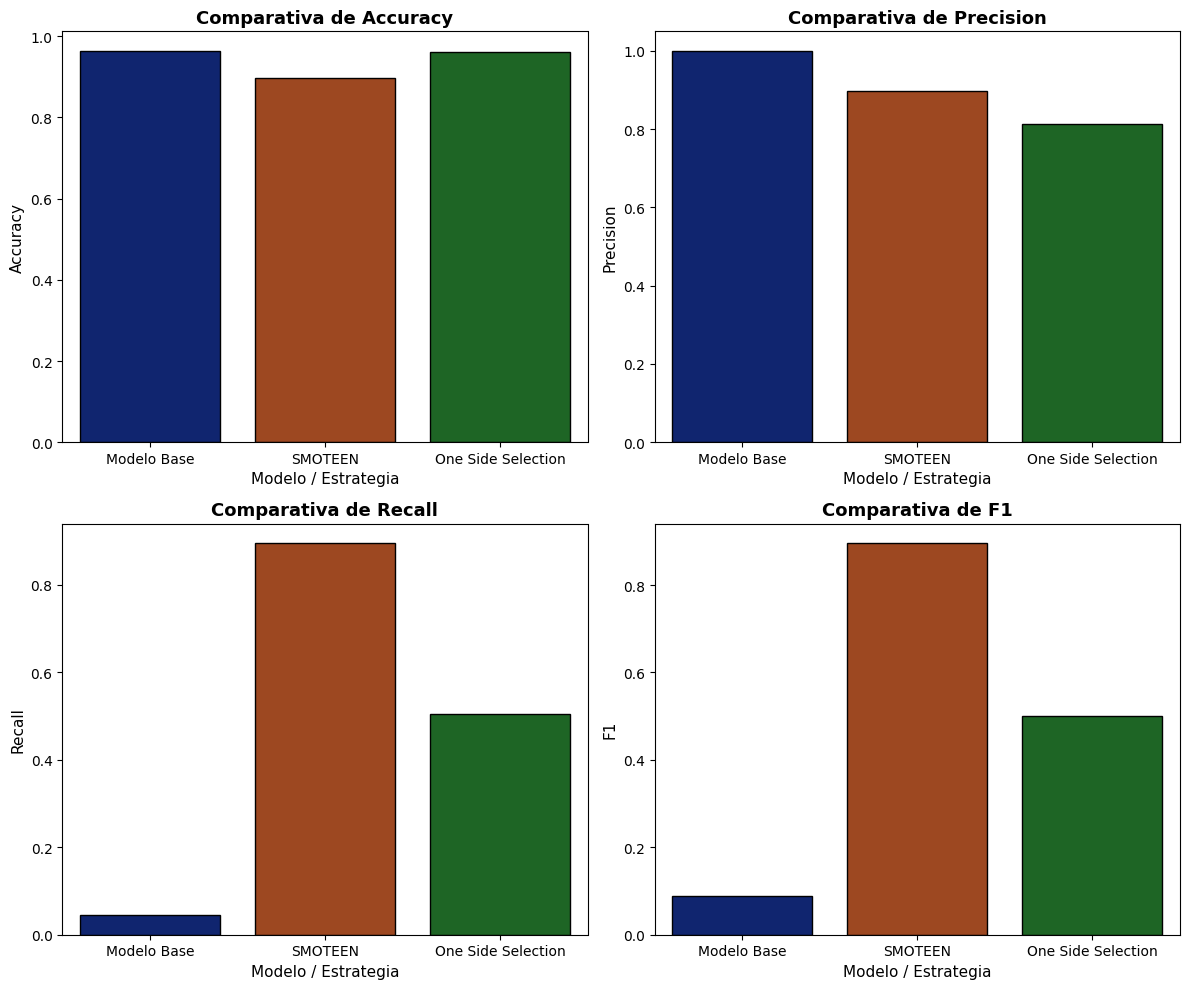

In [67]:
## Hacemos una grafica para comparar las metricas
data = {
    'Modelo': ['Modelo Base', 'SMOTEEN', 'One Side Selection'],
    'Accuracy': [acc_base, acc_smot, acc_oss],
    'Precision': [prec_base, prec_smot, prec_oss],
    'Recall': [rec_base, rec_smot, rec_oss],
    'F1': [f1_base, f1_smot, f1_oss]
}
df_res = pd.DataFrame(data)
col = ['Accuracy', 'Precision', 'Recall', 'F1']
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Aplanamos el array de ejes para recorrerlos fácilmente

# 3. Generar una gráfica independiente para cada métrica
for i, cols in enumerate(col):
    ax = axes[i]
    sns.barplot(
        data=df_res,
        x='Modelo',
        y=cols,
        ax=ax,
        hue='Modelo',
        palette='dark',
        legend=False,
        edgecolor='black'
      )

    ax.set_title(f'Comparativa de {cols}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Modelo / Estrategia', fontsize=11)
    ax.set_ylabel(cols, fontsize=11)
    plt.tight_layout()
plt.show()

#### Analizar si Accuracy es suficiente para evaluar el problema.
Accuracy no suele ser muy recomendable en dataset desbalanceados como este, ya que trata a ambas clases por igual, siendo que ignoraria si el los falsos positivos son masivos en la clase minoritaria, por eso en accuracy y precisition, el modelo base pudiera verse muy util, pero en recall y en f1 es realmente inservible el modelo teninendo menos de un 20% de efectividad

## 6.- Discusiones y Conclusiones

#### El impacto del desbalance sobre el desempeño del modelo.
Podemos ver que el desbalance hace que ciertas metricas se vean afectadas y no entreguen una precision real, sobre todo si nuestra prioridad fuera predecir la clase minoritaria

#### Las diferencias observadas entre SMOTEENN y One-Sided Selection.
One side selection, al mantener los casos reales y no crear datos artificialmente como si lo hace smoteen, puede mantener graficas mas reales, entonces no es tan habil cachando datos de la clase minoritaria o clasificando los datos que pudieran estar en la frontera de ambos, y en este caso smoteen pareciera que creo datos acertados ya que todas sus metricas se mantienen altas


#### Qué método produjo los mejores resultados y por qué.

En este caso y por las metricas podemos decir que que smoteenn fue el que mejores resultados dio en general, ya que es el que despunta en todas, aunque no fue el mas alto en accuracy, si fue el ams alto en las demas, asi que pudiera ser que en este caso el balancear las clases con datos ficticios pudo ayudar al modelo a tener mejor desempeño.